# RAPIDD verification for germanium

Use **Run All** to explore the saved comparisons. **RUN_LIVE** reruns the fixed-speed kernels and nuclear-input comparisons. **RUN_ABSOLUTE_RATES** in the last section builds the full pinned C calculator and reruns the O₁/O₁₁ rate benchmark. **RUN_EXTENDED_VALIDATION** reruns the remaining rate, folding, and inference checks. The switches default to off.

Run with a Python kernel that has NumPy, SciPy and Matplotlib installed. For the live mode, also install Git and GCC (on Windows, a WSL Python kernel is one option). From the WIMP-LEGEND repository root:

~~~sh
git clone https://github.com/cheekyparticle/RAPIDD_for_DM ../RAPIDD_for_DM
git -C ../RAPIDD_for_DM checkout c36b290abfc8f68dc4e53445bc18c185f4b466b0
~~~

The comparison covers the 14 diagonal, single-operator kernels of the frozen basis: O₁ and O₃–O₁₅. The original three operators were the poster workbench's single-operator benchmark. Off-diagonal operator interference, absolute halo-integrated rates, and detector-folded limits are separate checks. O₂ is outside the adopted basis.

[Comparison report](../docs/RAPIDD_COMPARISON.md) · [Conventions](../docs/NREFT_CONVENTIONS.md)

In [ ]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np

# Start Jupyter from this checkout or from its notebooks/ directory.
cwd = Path.cwd().resolve()
ROOT = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "analyses/validation/rapidd/compare_kernels.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from within the WIMP-LEGEND checkout.")

VALIDATION = ROOT / "analyses/validation/rapidd"
RUN_LIVE = False
RAPIDD_CHECKOUT = ROOT.parent / "RAPIDD_for_DM"

# Edit the grid only in live mode. Couplings are dimensionful (GeV^-2).
OPERATORS = (1, *range(3, 16))
ISOTOPES = (70, 72, 73, 74, 76)
RECOILS_KEV = (1.0, 10.0, 30.0)
MASSES_GEV = (40.0,)
SPEEDS_KM_S = (700.0,)
COUPLINGS = ((1.0, 1.0), (1.0, 0.0), (1.0, -0.7), (0.0, 1.0))

In [ ]:
if RUN_LIVE:
    for path in (ROOT / "src", VALIDATION):
        if str(path) not in sys.path:
            sys.path.insert(0, str(path))

    import compare_kernels
    import compare_responses

    kernels = compare_kernels.run(
        RAPIDD_CHECKOUT,
        operators=OPERATORS,
        isotopes=ISOTOPES,
        energies_keV=RECOILS_KEV,
        masses_GeV=MASSES_GEV,
        speeds_km_s=SPEEDS_KM_S,
        couplings=COUPLINGS,
    )
    responses = compare_responses.run(RAPIDD_CHECKOUT, include_phi_candidate=True)
else:
    saved = json.loads((VALIDATION / "all_operator_comparison.json").read_text())
    for report in saved.values():
        report["records"] = [
            dict(zip(report["columns"], row, strict=True)) for row in report["rows"]
        ]
    kernels, responses = saved["kernels"], saved["responses"]

assert kernels["rapidd_commit"] == responses["rapidd_commit"]
print("RAPIDD revision:", kernels["rapidd_commit"])
print("Kernel points:", len(kernels["records"]))
print("Nuclear-input points:", len(responses["records"]))
skipped = kernels.get("skipped_kinematic_points", [])
if skipped:
    print("Skipped forbidden (isotope, recoil, mass, speed) points:", len(skipped))
    print("First skipped point:", skipped[0])

RAPIDD revision: c36b290abfc8f68dc4e53445bc18c185f4b466b0
Kernel points: 840
Nuclear-input points: 640


## Which velocity enters the operator?

At fixed elastic recoil, the incoming velocity component along the momentum transfer has magnitude $v_{\min}=q/(2\mu_T)$. Removing it leaves $v_{T,\perp}^2=v^2-v_{\min}^2$. The parallel component supplies the recoil, so at $v=v_{\min}$ the transverse component vanishes.

Write the two RAPIDD form-factor terms as $F_0$ and $F_2$. Its pinned rate assembly weights them with the raw inverse-speed and speed moments, equivalent at fixed speed to $F_0+v^2 F_2$. The diagnostic evaluates $F_0+(v^2-v_{\min}^2)F_2$. At the halo-integral level the equivalent change is $\xi-v_{\min}^2\eta$ multiplying $F_2$, where $\xi=\int_{v>v_{\min}}d^3v\,f(\mathbf v)v$ and $\eta=\int_{v>v_{\min}}d^3v\,f(\mathbf v)/v$.

The shared-input comparison isolates the apparent omission to the pinned RAPIDD assembly. Upstream confirmation and full rate-level tests remain open. The diagnostic leaves both implementations' production equations as shipped. For O₈ in even Ge, the $\Delta$ contribution vanishes, so the relative excess is $v_{\min}^2/(v^2-v_{\min}^2)$.

[RAPIDD rate assembly](https://github.com/cheekyparticle/RAPIDD_for_DM/blob/c36b290abfc8f68dc4e53445bc18c185f4b466b0/lib/source/difRateGen.c#L112-L127) · [Halo moments](https://github.com/cheekyparticle/RAPIDD_for_DM/blob/c36b290abfc8f68dc4e53445bc18c185f4b466b0/lib/source/halo.c#L95-L154)

Operator      Raw max  Shifted max   Common zeros  Zero mismatch
O1          7.616e-14    7.616e-14              0              0
O3          1.898e-05    9.770e-15              0              0
O4          1.655e-13    1.655e-13             48              0
O5          4.262e-01    2.849e-13              0              0
O6          3.506e-13    3.506e-13             48              0
O7          4.196e-01    1.806e-13             48              0
O8          4.262e-01    8.060e-14              0              0
O9          3.284e-13    3.284e-13             48              0
O10         3.745e-13    3.745e-13             48              0
O11         2.978e-13    2.978e-13              0              0
O12         2.648e-05    7.994e-15              0              0
O13         6.664e-05    2.887e-15             48              0
O14         4.196e-01    8.005e-14             48              0
O15         1.898e-05    9.770e-15              0              0


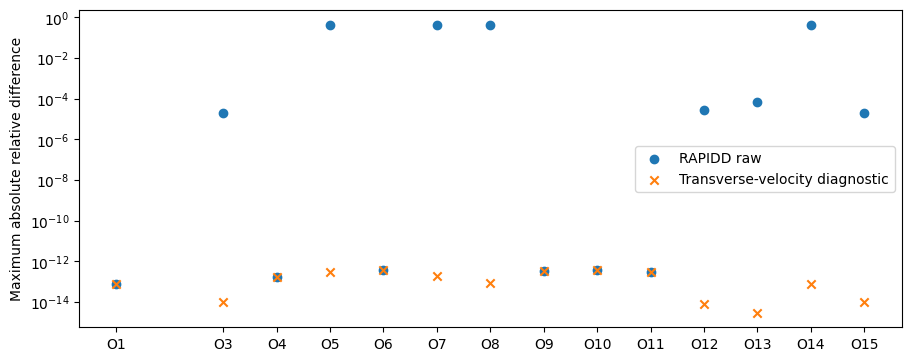

In [ ]:
def max_abs_relative(rows, field):
    return max((abs(row[field]) for row in rows if row[field] is not None), default=np.nan)


raw_key = "rapidd_raw_velocity_kernel"
shifted_key = "shifted_velocity_diagnostic"
columns = ("raw_relative_difference", "shifted_relative_difference")
operators = sorted({row["operator"] for row in kernels["records"]})
kernel_maxima = []
print(f"{'Operator':>8} {'Raw max':>12} {'Shifted max':>12} {'Common zeros':>14} {'Zero mismatch':>14}")
for op in operators:
    rows = [row for row in kernels["records"] if row["operator"] == op]
    maxima = [max_abs_relative(rows, field) for field in columns]
    common_zeros = sum(row["ours"] == row[raw_key] == row[shifted_key] == 0 for row in rows)
    zero_mismatches = sum(
        (row["ours"] == 0) != (row[shifted_key] == 0) for row in rows
    )
    kernel_maxima.append(maxima)
    print(f"O{op:<7} {maxima[0]:12.3e} {maxima[1]:12.3e} {common_zeros:14d} {zero_mismatches:14d}")

if np.any(np.asarray(kernel_maxima) > 0):
    fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
    for values, marker, label in zip(
        np.asarray(kernel_maxima).T, ("o", "x"), ("RAPIDD raw", "Transverse-velocity diagnostic")
    ):
        ax.scatter(operators, np.where(values > 0, values, np.nan), marker=marker, label=label)
    ax.set(yscale="log", ylabel="Maximum absolute relative difference",
           xticks=operators, xticklabels=[f"O{op}" for op in operators])
    ax.legend()
    plt.show()
elif operators:
    print("No positive relative differences to show on the log scale.")
else:
    print("No allowed kernel points in this grid.")

## Inspect a recoil slice

Change the isotope, operator and coupling pair below. The numerator is the C kernel and the denominator is WIMP-LEGEND on the same nuclear inputs. Exact-zero denominators are reported in the table above. For O₁₂ and O₁₃ the shared fixture uses RAPIDD's $Pp/Pp+Pt/Pt$ combination as the diagnostic $\tilde{\Phi}'$ response.

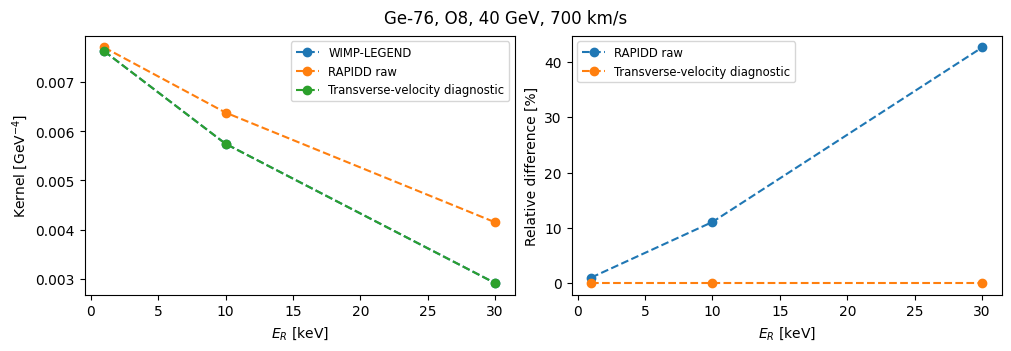

In [ ]:
A_PLOT, OP_PLOT = 76, 8
MASS_PLOT_GEV, SPEED_PLOT_KM_S = 40.0, 700.0
CP_PLOT, CN_PLOT = 1.0, 1.0

slice_rows = sorted(
    (r for r in kernels["records"] if
     (r["A"], r["operator"], r["mchi_GeV"], r["v_km_s"], r["cp"], r["cn"])
     == (A_PLOT, OP_PLOT, MASS_PLOT_GEV, SPEED_PLOT_KM_S, CP_PLOT, CN_PLOT)),
    key=lambda r: r["ER_keV"],
)
if slice_rows:
    fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
    recoil = [row["ER_keV"] for row in slice_rows]
    for field, label in (("ours", "WIMP-LEGEND"), (raw_key, "RAPIDD raw"),
                         (shifted_key, "Transverse-velocity diagnostic")):
        left.plot(recoil, [row[field] for row in slice_rows], "o--", label=label)
    for field, label in zip(columns, ("RAPIDD raw", "Transverse-velocity diagnostic")):
        values = np.array([row[field] for row in slice_rows], dtype=float)
        right.plot(recoil, 100 * values, "o--", label=label)
    left.set(ylabel=r"Kernel [GeV$^{-4}$]")
    right.set(ylabel="Relative difference [%]")
    for ax in (left, right):
        ax.set(xlabel=r"$E_R$ [keV]")
        ax.legend(fontsize="small")
    fig.suptitle(f"Ge-{A_PLOT}, O{OP_PLOT}, {MASS_PLOT_GEV:g} GeV, {SPEED_PLOT_KM_S:g} km/s")
    plt.show()
else:
    print("This slice has no points. Set the controls to values present in the grid.")

## Compare nuclear inputs at matching $y=(qb/2)^2$

Here each code uses its own nuclear input. The original comparison omitted $\tilde{\Phi}'$. The source contains $Pp/Pp$ entries for Ge-73 and the O₁₂/O₁₃ routines sum them with $Pt/Pt$. The candidate mapping is plotted as $\tilde{\Phi}'$ below. Shared-input kernel agreement for those operators checks the contraction. The size and origin of the nuclear-input difference remain a separate question.

[RAPIDD Ge-73 table](https://github.com/cheekyparticle/RAPIDD_for_DM/blob/c36b290abfc8f68dc4e53445bc18c185f4b466b0/lib/source/effFormFact.c#L339-L342)

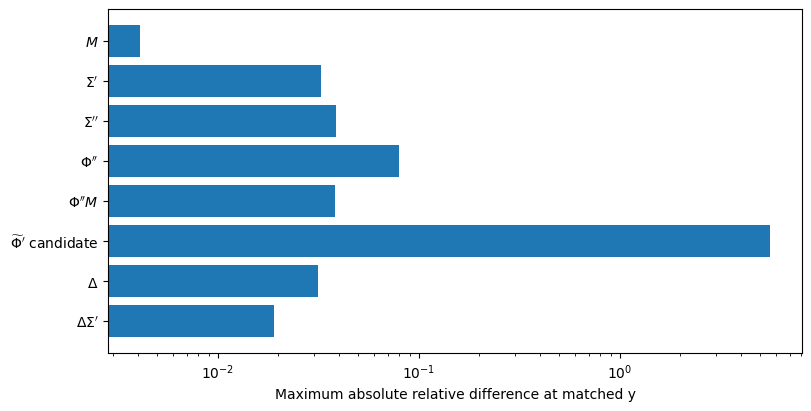

Nuclear-input zero mismatches: 0
Ge-73 candidate response (neutron–neutron)
y=0   RAPIDD/AFH=5
y=0.001   RAPIDD/AFH=5.0001
y=0.01   RAPIDD/AFH=5.0136
y=0.1   RAPIDD/AFH=6.5926


In [5]:
channel_labels = {
    "M": r"$M$",
    "Sigma_prime": r"$\Sigma'$",
    "Sigma_double_prime": r"$\Sigma''$",
    "Phi_double_prime": r"$\Phi''$",
    "Phi_double_prime_M": r"$\Phi''M$",
    "Phi_tilde_prime": r"$\widetilde{\Phi}'$ candidate",
    "Delta": r"$\Delta$",
    "Delta_Sigma_prime": r"$\Delta\Sigma'$",
}
response_maxima = {
    channel: max_abs_relative(
        (r for r in responses["records"] if r["channel"] == channel),
        "relative_difference",
    )
    for channel in channel_labels
}
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.barh(list(channel_labels.values()), list(response_maxima.values()))
ax.set(xscale="log", xlabel="Maximum absolute relative difference at matched y")
ax.invert_yaxis()
plt.show()

zero_mismatches = [
    row for row in responses["records"]
    if (row["rapidd"] == 0) != (row["afh_source"] == 0)
]
print("Nuclear-input zero mismatches:", len(zero_mismatches))
phi_rows = [
    row for row in responses["records"]
    if row["A"] == 73 and row["channel"] == "Phi_tilde_prime"
    and row["n1"] == row["n2"] == 1
]
print("Ge-73 candidate response (neutron–neutron)")
for row in phi_rows:
    print(f"y={row['y']:g}   RAPIDD/AFH={1 + row['relative_difference']:.5g}")

## RAPIDD Coefficients

In [6]:
from math import exp, pi

coeff = (0.4625, -0.79698, 0.69, -0.287, 0.071, -0.0088)

for row in responses["records"]:
    if (row["A"], row["channel"], row["n1"], row["n2"]) != (73, "Phi_tilde_prime", 1, 1):
        continue

    y, afh = row["y"], row["afh_source"]
    raw = row["rapidd"]
    diagnostic = (4 * pi / 10) * exp(-2 * y) * sum(
        c * y**k for k, c in enumerate(coeff)
    )
    print(f"{y:g}  raw={raw/afh:.9f}  prefactor={raw/(5*afh):.9f}  both={diagnostic/afh:.9f}")

0  raw=5.000008122  prefactor=1.000001624  both=1.000001624
0.001  raw=5.000141405  prefactor=1.000028281  both=1.000001617
0.01  raw=5.013557473  prefactor=1.002711495  both=1.000001468
0.1  raw=6.592585113  prefactor=1.318517023  both=0.999991335


## Absolute isotope recoil rates

This first rate benchmark compares O₁ and O₁₁ on Ge-73 and Ge-76 at 5 and 40 GeV. Both operators use the coherent \(M\) response and have no transverse-velocity term. The rates are per kg of the pure isotope in events/(kg day keV\(_{\rm nr}\)). The last grid point is above the elastic endpoint.

- [run_absolute_rates](../analyses/validation/rapidd/compare_rates.py) builds the pinned C calculator in a temporary directory, initializes a fixed-speed SHM halo table, and calls the individual isotope rate. At each recoil point it gives the WIMP-LEGEND rate integrator the same RAPIDD nuclear input.
- [rate_residuals](../analyses/validation/rapidd/compare_rates.py) computes \(R_{\rm RAPIDD}-R_{\rm WIMP}\), relative rate residuals, and relative residuals in the mean inverse speed \(\eta(v_{\min})\). Relative rate residuals are displayed where the reference rate exceeds \(10^{-6}\) of its peak.
- [plot_absolute_rates](../analyses/validation/rapidd/compare_rates.py) plots the absolute spectra and relative residuals for each isotope, mass, and operator.

RAPIDD uses one isotope mass for the recoil kinematics and a slightly different mass inside its form factors. We use its kinematic mass in both rate integrations. The comparison matches the explicit O₁₁ \(q^2\) prefactor with the recorded ratio \(m_{\rm form\ factor}/m_{\rm kinematics}\). The saved output includes the WIMP-LEGEND rate before and after that diagnostic adjustment.

The residual plots divide out the offset predicted by RAPIDD’s hard-coded unit constant compared with WIMP-LEGEND’s SI-derived constant. The table reports both the raw residual and the residual after this independently calculated ratio.

Leave the flag off to use the saved rates. For a live run, install CMake, a C compiler, and GSL development files (for example cmake, build-essential, and libgsl-dev on Debian/Ubuntu, including WSL) and use the clean pinned RAPIDD checkout from the first section.

In [ ]:
RUN_ABSOLUTE_RATES = False
RATE_ISOTOPES = (73, 76)
RATE_MASSES_GEV = (5.0, 40.0)
RATE_OPERATORS = (1, 11)
RATE_COUPLINGS_GEV_MINUS2 = (1e-6, 1e-6)

for path in (ROOT / "src", VALIDATION):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from compare_rates import plot_absolute_rates, rate_residuals, run_absolute_rates

if RUN_ABSOLUTE_RATES:
    absolute_rates = run_absolute_rates(
        RAPIDD_CHECKOUT,
        isotopes=RATE_ISOTOPES,
        masses_GeV=RATE_MASSES_GEV,
        operators=RATE_OPERATORS,
        couplings=RATE_COUPLINGS_GEV_MINUS2,
    )
else:
    absolute_rates = json.loads((VALIDATION / "absolute_rate_comparison.json").read_text())

print(f"RAPIDD {absolute_rates['rapidd_commit']}")
print(f"SHM (km/s) {absolute_rates['halo_km_s']}")
print(f"{len(absolute_rates['cases'])} absolute spectra")

In [ ]:
unit_ratio = absolute_rates["unit_prefactor_ratio"]
print(f"Predicted offset from unit constants: {100*(unit_ratio - 1):+.6f}%")
print(f"{'Case':<20} {'Max |ΔR/R|':>13} {'After unit ratio':>17} {'Max |Δη/η|':>13} {'RAPIDD above cutoff':>22}")
for case in absolute_rates["cases"]:
    energy, _, rate_relative, eta_relative = rate_residuals(case)
    label = f"Ge-{case['A']} O{case['operator']} {case['mchi_GeV']:g} GeV"
    finite = rate_relative[np.isfinite(rate_relative)]
    max_rate = max(np.abs(finite), default=np.nan)
    after_units = max(np.abs((1 + finite)/unit_ratio - 1), default=np.nan)
    max_eta = max(np.abs(eta_relative[np.isfinite(eta_relative)]), default=np.nan)
    native = np.asarray(case["rapidd_rate"])
    above = max(np.abs(native[energy > case["endpoint_keV"]]), default=np.nan)
    print(f"{label:<20} {max_rate:13.3e} {after_units:17.3e} {max_eta:13.3e} {above:22.3e}")

figures = plot_absolute_rates(absolute_rates)
plt.show()

## Extended verification

[run_extended](../analyses/validation/rapidd/validate_extended.py) builds RAPIDD and compares all 14 single-operator rates, all seven interference pairs and two zero controls. Both codes use the same pointwise nuclear inputs for this stage. For an interference pair, reversing one coupling and taking half the difference isolates the signed cross term.

The raw rates come from the stock C calls. The aligned diagnostic uses the same rate-unit constant for both terms and replaces the C speed moment by the transverse moment \(\xi-v_{\min}^2\eta\), using the signed C form factors in the order selected by the stock calculator. The reported gap is \(|R_C-R_W|/\max(|R_C|,|R_W|)\), with a zero gap when both values vanish. Use the signed worst-case values to interpret large gaps in small interference terms.

The Ge mixture check verifies the weights used by the C wrapper and compares the effect of converting the same number fractions to mass fractions. A separate subsection uses common kinematics and halo to compare the two nuclear tables, including a diagnostic swap of only the \(^{73}\)Ge candidate \(\widetilde\Phi'\) response.

[run_folding_checks](../analyses/validation/rapidd/validate_folding.py) compares native unsmeared counts, tests whether RAPIDD's generic smearing function responds to its width argument, verifies a shared Ge folding benchmark by independent quadrature, and compares the fixed-background Asimov likelihood at a common threshold.

In [ ]:
RUN_EXTENDED_VALIDATION = False

from validate_extended import run_extended

if RUN_EXTENDED_VALIDATION:
    extended = run_extended(RAPIDD_CHECKOUT)
else:
    extended = json.loads((VALIDATION / "extended_comparison.json").read_text())

print("RAPIDD revision:", extended["rapidd_commit"])
for key, label in (("singles", "Single-operator"), ("mixed", "Interference")):
    print(f"{label} cases: {sum(row['cases'] for row in extended[key])}")
    print(f"{'Operator(s)':<16} {'Raw max gap':>14} {'Aligned max gap':>17}")
    for row in extended[key]:
        name = f"O{row['operator']}" if key == "singles" else f"O{row['first']} / O{row['second']}"
        print(f"{name:<16} {row['max_raw_gap']:14.3e} {row['max_aligned_gap']:17.3e}")

In [ ]:
def max_relative(rows, first, second):
    return max((abs(row[first]/row[second] - 1) for row in rows if row[second]), default=np.nan)

pair89 = next(row for row in extended["mixed"] if (row["first"], row["second"]) == (8, 9))
print(f"O8/O9 reversed-order diagnostic max gap: {pair89['max_reverse_order_gap']:.3e}")
print("Negative signed C rates from the rounded inputs:")
for row in extended["singles"]:
    if row["negative_signed_count"]:
        example = row["worst_raw"]
        print(f"O{row['operator']}: {row['negative_signed_count']} cases, "
              f"example signed rate {example['rapidd_signed']:.4g}, "
              f"wrapper {example['rapidd_raw']:.4g}")

mix = extended["mixtures"]
print(f"RAPIDD raw Ge weights sum: {sum(extended['raw_ge_weights']):.6f}")
print(f"Ge wrapper vs raw-weighted sum: {max_relative(mix, 'rapidd_ge', 'rapidd_number_sum'):.3e}")
print(f"Normalized number vs mass weighted C rates: "
      f"{max_relative(mix, 'rapidd_normalized_number_sum', 'rapidd_mass_sum'):.3%}")
print("Native table comparison for natural Ge with common kinematics")
for op in (1, 8, 11, 12, 13):
    rows = [row for row in mix if row["operator"] == op]
    print(f"O{op}: max |RAPIDD table/AFH - 1| = "
          f"{max_relative(rows, 'wimp_matched_mass_sum', 'wimp_afh_mass_sum'):.3%}")
print("Ge-73 candidate-only swap at fixed kinematics")
for op in (12, 13):
    rows = [row for row in extended["phi_candidate"] if row["operator"] == op]
    print(f"O{op}: max |candidate/AFH - 1| = {max_relative(rows, 'candidate_only', 'afh'):.3%}")

fold = extended["folding"]
print(f"Unsmeared bin gap: {np.max(np.abs(np.array(fold['stock_c_bins']) / fold['wimp_unsmeared'] - 1)):.3e}")
print("Native smearing widths (keV):", fold["stock_smearing_sigma_keV"])
print("Native smearing counts:", fold["stock_smearing_counts"])
print(f"Gaussian folding gap: {np.max(np.abs(np.array(fold['gaussian_wimp']) / fold['gaussian_reference'] - 1)):.3e}")
print(f"Matched Asimov strength limits: RAPIDD {fold['mu_rapidd_matched']:.8g}, WIMP-LEGEND {fold['mu_wimp']:.8g}")
print(f"RAPIDD strength at its default q=2.706: {fold['mu_rapidd_default_threshold']:.8g}")